## Step 1: Dataset Selection and Loading
I selected the Adult Income dataset from the UCI Machine Learning Repository. It contains demographic and employment information, including age, education, occupation, and working hours. The target column is "income" which indicates whether a person's income is above or below $50,000. The dataset contains both numerical and categorical features, as well as missing values that must be handled before machine learning.

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Column names for the dataset
columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

# Load the dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

df = pd.read_csv(
    url,
    names=columns,
    na_values="?",
    skipinitialspace=True
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Step 2: Exploratory Data Analysis (EDA)
In this step, I will examine the dataset's structure, data types, first few rows, and statistical summaries. I will also visualize the target distribution and explore patterns in numerical and categorical features. This will help me understand the data before cleaning and preprocessing it.

In [19]:


print("Shape:", df.shape)

print("\nDataset information:")
df.info()
print("\nFirst five rows:")
display(df.head())

print("\nStatistical summary:")
display(df.describe(include="all"))


Shape: (32561, 15)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

First five rows:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



Statistical summary:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
count,32561.000000,30725,3.256100e+04,32561,32561.000000,32561,30718,32561,32561,32561,32561.000000,32561.000000,32561.000000,31978,32561
unique,NaN,8,NaN,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


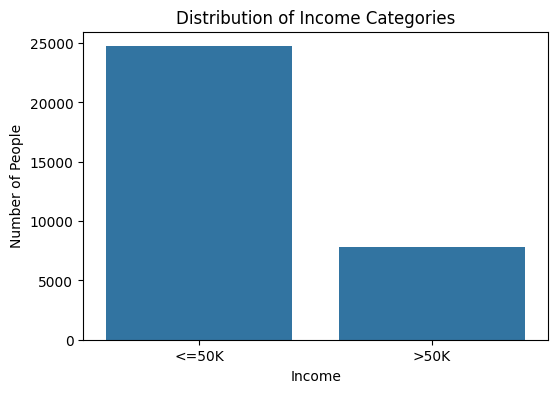

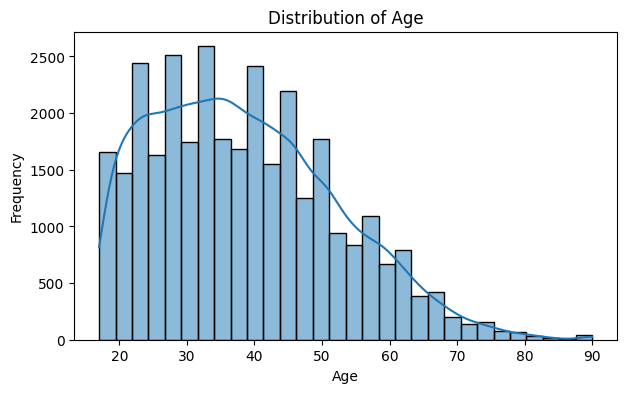

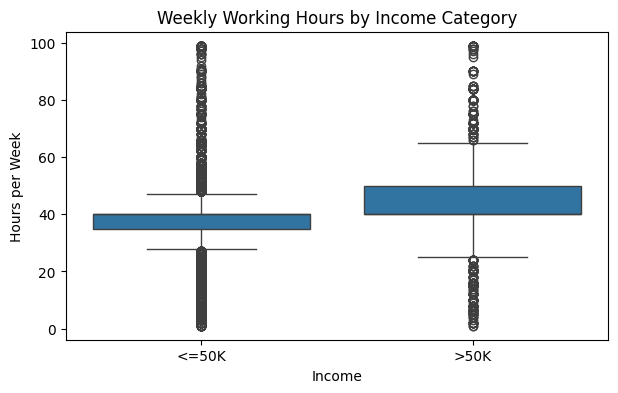

In [20]:

# Chart 1: Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="income")
plt.title("Distribution of Income Categories")
plt.xlabel("Income")
plt.ylabel("Number of People")
plt.show()

# Chart 2: Distribution of age
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", bins=30, kde=True)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

# Chart 3: Weekly working hours by income
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="income", y="hours_per_week")
plt.title("Weekly Working Hours by Income Category")
plt.xlabel("Income")
plt.ylabel("Hours per Week")
plt.show()


### EDA Observations

**1. Income Distribution:** The countplot shows the number of people in each income category. The dataset contains two income classes: <=50K and >50K. The lower-income category has more records than the higher-income category, indicating that the target classes are imbalanced.

**2. Age Distribution:** The histogram shows how ages are distributed in the dataset. Most individuals are in the working-age range, while fewer records appear at the youngest and oldest ages.

**3. Weekly Working Hours by Income:** The boxplot compares weekly working hours between the two income categories. It shows the median, spread, and possible outliers in working hours for each group. This helps us explore whether working hours differ between income groups.

## Step 3: Data Cleaning
In this step, I will check the dataset for duplicate rows and missing values. I will remove duplicate records to avoid counting the same observation more than once. I will also identify unnecessary columns and decide how to handle missing values before preparing the data for machine learning.

In [21]:

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 24


In [22]:

df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)


Shape after removing duplicates: (32537, 15)


In [23]:


missing_counts = df.isnull().sum()

print("Missing values per column:")
display(missing_counts.to_frame(name="Missing Count"))

print("Total missing values:", df.isnull().sum().sum())


Missing values per column:


,Missing Count
age,0
workclass,1836
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,1843
relationship,0
race,0
sex,0


Total missing values: 4261


### Data Cleaning Findings

I found 24 duplicate rows in the original dataset and removed them. After removing duplicates, the dataset contained 32,537 rows and 15 columns.

The missing-value analysis identified three columns with missing data: "workclass" had 1,836 missing values, "occupation" had 1,843, and "native_country" had 582. The total number of missing values was 4,261.

I decided to retain these records because they still contain useful information. I will fill missing numerical values using the median and missing categorical values using the most frequent value during preprocessing.

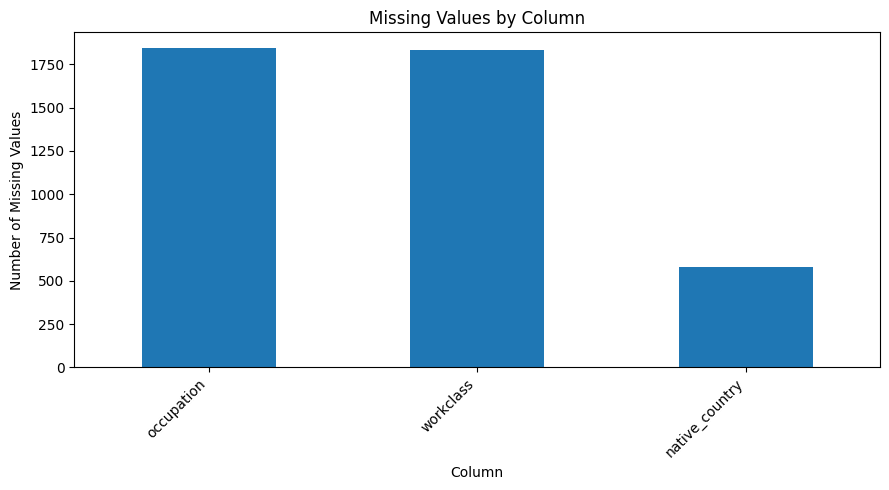

In [24]:

missing_counts = df.isnull().sum()

missing_counts = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

plt.figure(figsize=(9, 5))
missing_counts.plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Unnecessary or Redundant Columns
I decided to remove "fnlwgt" because it is a census sampling weight and is not needed for this simplified prediction task. I also removed "education" because "education_num" already provides a numerical representation of education level. These choices simplify the feature set while retaining the features needed for the project.

In [25]:

df = df.drop(columns=["fnlwgt", "education"])

print("Shape after dropping columns:", df.shape)
print("Remaining columns:")
print(df.columns.tolist())


Shape after dropping columns: (32537, 13)
Remaining columns:
['age', 'workclass', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']


### Missing-Value Decisions

I will retain the rows containing missing feature values and handle them during preprocessing. Missing numerical values will be filled with the median, while missing categorical values will be filled with the most frequent value. This approach keeps useful records and ensures that imputation values are learned from the training data only. I will not fill the target column because records without a known target cannot be used for supervised learning.

In [26]:

print("Missing values in target column:")
print(df["income"].isnull().sum())


Missing values in target column:
0


## Step 4: Feature Engineering

Feature engineering means creating new features from existing columns to provide additional information to a machine learning model.

I created "capital_total" by combining capital gain and capital loss. I also created "is_married" to indicate whether a person belongs to the "Married-civ-spouse" category. These features may help the model identify patterns related to income.

In [27]:

df["capital_total"] = df["capital_gain"] + df["capital_loss"]

df["is_married"] = (
    df["marital_status"] == "Married-civ-spouse"
).astype(int)

print("New features created successfully!")

display(df[[
    "capital_gain",
    "capital_loss",
    "capital_total",
    "marital_status",
    "is_married"
]].head())

print("Updated dataset shape:", df.shape)


New features created successfully!


,capital_gain,capital_loss,capital_total,marital_status,is_married
0,2174,0,2174,Never-married,0
1,0,0,0,Married-civ-spouse,1
2,0,0,0,Divorced,0
3,0,0,0,Married-civ-spouse,1
4,0,0,0,Married-civ-spouse,1


Updated dataset shape: (32537, 15)


## Step 5: Feature and Target Selection

I selected "income" as the target variable because the goal is to predict income categories. The variable "X" contains all input features, while "y" contains the target labels. This is a classification problem because the target consists of two categories.

In [28]:

X = df.drop(columns=["income"])

y = df["income"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))


X shape: (32537, 14)
y shape: (32537,)

Target distribution:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64

Target proportions:
income
<=50K    0.759074
>50K     0.240926
Name: proportion, dtype: float64


## Step 6: Train/Test Split

I divided the dataset into training and testing sets using an 80/20 split and "random_state=42" to make the results reproducible. I used "stratify=y" because the target is categorical and the two income classes are imbalanced. This helps maintain approximately the same class proportions in both sets.

In [29]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Print dataset sizes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Check class proportions
print("\nTraining set class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting set class proportions:")
print(y_test.value_counts(normalize=True))


X_train shape: (26029, 14)
X_test shape: (6508, 14)
y_train shape: (26029,)
y_test shape: (6508,)

Training set class proportions:
income
<=50K    0.759076
>50K     0.240924
Name: proportion, dtype: float64

Testing set class proportions:
income
<=50K    0.759066
>50K     0.240934
Name: proportion, dtype: float64


## Step 7: Data Preprocessing

In this step, I will prepare the training and testing features for machine learning. I will fill missing numerical values using the median and missing categorical values using the most frequent value. I will use StandardScaler to scale numerical features and OneHotEncoder to convert categorical features into numerical representations. I will combine these operations using ColumnTransformer. To avoid data leakage, I will fit the preprocessing pipeline only on the training data and use it to transform the testing data.

In [30]:

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

print("\nNumber of numerical columns:", len(numeric_features))
print("Number of categorical columns:", len(categorical_features))


Numerical columns:
['age', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'capital_total', 'is_married']

Categorical columns:
['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Number of numerical columns: 7
Number of categorical columns: 7


In [31]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Pipeline for numerical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline for categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [32]:

# Save the original split features for clarity
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()

# Learn preprocessing values from training data and transform it
X_train_processed = preprocessor.fit_transform(X_train_raw)

# Apply the learned preprocessing to testing data only
X_test_processed = preprocessor.transform(X_test_raw)

# Replace X variables with the final processed features
X_train = X_train_processed
X_test = X_test_processed

print("Preprocessing completed successfully!")
print("Processed training shape:", X_train.shape)
print("Processed testing shape:", X_test.shape)


Preprocessing completed successfully!
Processed training shape: (26029, 90)
Processed testing shape: (6508, 90)


## Step 8: Final Checks

I will verify the shapes of the processed training and testing features and check that no missing values remain. I will also confirm that the preprocessing pipeline was fitted using the training data only. The target labels remain separate from the input features, and the final outputs are X_train, X_test, y_train, and y_test.

In [33]:

print("Final output shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check for missing values in processed features
print("\nMissing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_test:", np.isnan(X_test).sum())

# Check target labels
print("\nMissing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

# Verify that the preprocessing pipeline was fitted
print("\nPreprocessing fitted:", hasattr(preprocessor, "transformers_"))

print("\nAll final checks completed.")


Final output shapes:
X_train: (26029, 90)
X_test: (6508, 90)
y_train: (26029,)
y_test: (6508,)

Missing values in X_train: 0
Missing values in X_test: 0

Missing values in y_train: 0
Missing values in y_test: 0

Preprocessing fitted: True

All final checks completed.
